# 0a

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['figure.figsize'] = (8,6)
plt.rcParams['font.size'] = 12

In [2]:
def f(x):
    return x**3 - 2*x**2 + x

def f_prime_analytical(x):
    return 3*x**2 - 4*x + 1

def numerical_derivative(func, x, h=1e-5):
    return (func(x+h) - func (x-h)) / (2*h)

def autograd_derivative(func, x_val):
    x = torch.tensor(x_val, dtype=torch.float64, requires_grad=True)
    y = func(x)
    y.backward()
    return x.grad.item()

test_points = [-1.0, 0.0, 0.5, 1.0, 2.0, 3.0]
print(f"{'x':>6} | {'Analytical':>12} | {'Finite Diff':>12} | {'Autograd':>12} | {'FD Error':>12}")
print('-' * 70)

for x in test_points:
    exact = f_prime_analytical(x)
    fd = numerical_derivative(f,x)
    ag = autograd_derivative(f,x)
    print(f"{x:6.1f} | {exact:12.6f} | {fd:12.6f} | {ag:12.6f} | {abs(fd - exact):12.2e}")


     x |   Analytical |  Finite Diff |     Autograd |     FD Error
----------------------------------------------------------------------
  -1.0 |     8.000000 |     8.000000 |     8.000000 |     1.19e-10
   0.0 |     1.000000 |     1.000000 |     1.000000 |     1.00e-10
   0.5 |    -0.250000 |    -0.250000 |    -0.250000 |     1.01e-10
   1.0 |     0.000000 |     0.000000 |     0.000000 |     9.44e-11
   2.0 |     5.000000 |     5.000000 |     5.000000 |     1.66e-10
   3.0 |    16.000000 |    16.000000 |    16.000000 |     1.05e-10


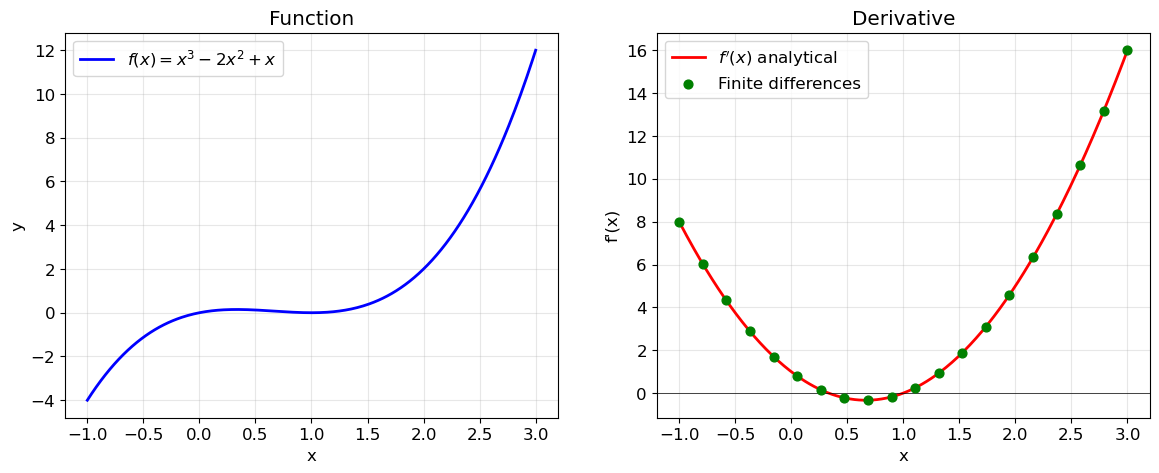

In [3]:
x = np.linspace(-1, 3, 300)

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(14,5))

ax1.plot(x,f(x), 'b-', linewidth=2, label='$f(x) = x^3 - 2x^2 + x$')
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Function")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(x, f_prime_analytical(x), 'r-', linewidth=2, label="$f'(x)$ analytical")
x_sparse = np.linspace(-1, 3, 20)
fd_vals = [numerical_derivative(f,xi) for xi in x_sparse]
ax2.scatter(x_sparse, fd_vals, c='green', s=40, zorder=5, label='Finite differences')
ax2.axhline(y=0, color='k', linewidth=0.5)
ax2.set_xlabel('x'); ax2.set_ylabel("f'(x)")
ax2.set_title('Derivative'); ax2.legend(); ax2.grid(True, alpha=0.3)

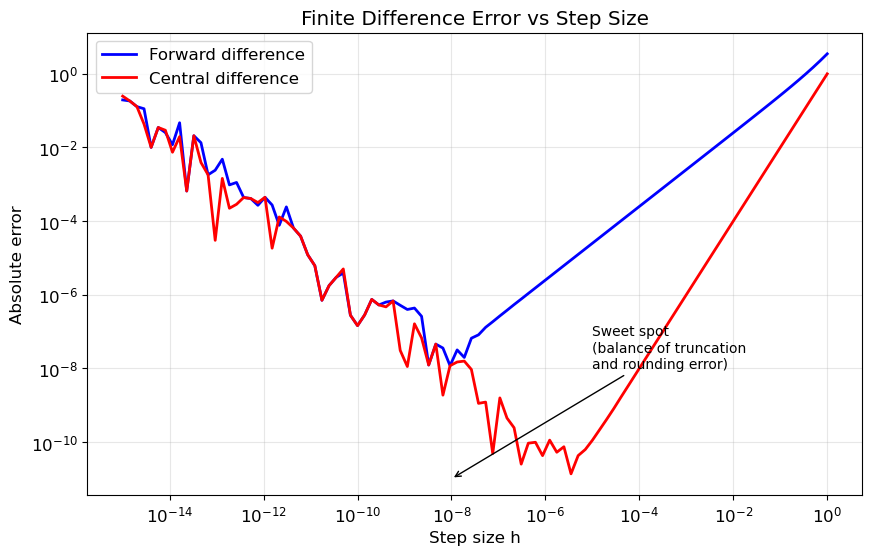

In [4]:
x0 = 1.5
exact = f_prime_analytical(x0)

h_values = np.logspace(-15, 0, 100)

forward_errors = [ abs((f(x0+h) - f(x0))/ h - exact) for h in h_values]
central_errors = [ abs((f(x0+h) - f(x0-h))/(2*h) - exact) for h in h_values]


plt.figure(figsize=(10, 6))
plt.loglog(h_values, forward_errors, 'b-', label='Forward difference', linewidth=2)
plt.loglog(h_values, central_errors, 'r-', label='Central difference', linewidth=2)
plt.xlabel('Step size h')
plt.ylabel('Absolute error')
plt.title('Finite Difference Error vs Step Size')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.annotate('Sweet spot\n(balance of truncation\nand rounding error)',
             xy=(1e-8, 1e-11), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='black'),
             xytext=(1e-5, 1e-8))
plt.show()

In [7]:
x = torch.tensor(2.0, requires_grad=True)
y = x**3 - 2*x**2 + x

dy_dx = torch.autograd.grad(y,x, create_graph=True)[0]
print(f"f(2)   = {y.item():.4f}")
print(f"f'(2)  = {dy_dx.item():.4f}  (analytical: {3*4 - 4*2 + 1})")

d2y_dx2 = torch.autograd.grad(dy_dx,x, create_graph=True)[0]
print(f"f''(2) = {d2y_dx2.item():.4f}  (analytical: {6*2 - 4})")

d3y_dx3 = torch.autograd.grad(d2y_dx2,x, create_graph=True)[0]
print(f"f'''(2)= {d3y_dx3.item():.4f}  (analytical: 6)")

f(2)   = 2.0000
f'(2)  = 5.0000  (analytical: 5)
f''(2) = 8.0000  (analytical: 8)
f'''(2)= 6.0000  (analytical: 6)


In [2]:
def scalar_field(x,y):
    return np.sin(x) * np.cos(y) + 0.5 * x

def gradient_analytical(x,y):
    df_dx = np.cos(x) * np.cos(y) + 0.5 
    df_dy = -np.sin(x) * np.sin(y)
    return df_dx, df_dy

def gradient_numerical(func, x, y, h=1e-5):
    df_dx = (func(x+h,y) - func(x-h,y)) / (2*h)
    df_dy = (func(x,y+h) - func(x,y-h)) / (2*h) 
    return df_dx, df_dy

def gradient_autograd(x_val, y_val):
    x = torch.tensor(x_val, requires_grad=True)
    y = torch.tensor(y_val, requires_grad=True)
    f = torch.sin(x) * torch.cos(y) + 0.5 * x
    f.backward()
    return x.grad.item(), y.grad.item()

x0, y0 = 1.0, 0.5
print(f"  Analytical:  {gradient_analytical(x0, y0)}")
print(f"  Numerical:   {gradient_numerical(scalar_field, x0, y0)}")
print(f"  Autograd:    {gradient_autograd(x0, y0)}")

  Analytical:  (np.float64(0.9741598817790379), np.float64(-0.4034226801113349))
  Numerical:   (np.float64(0.9741598817725182), np.float64(-0.4034226801064022))
  Autograd:    (0.9741598963737488, -0.40342268347740173)


Text(0, 0.5, 'y')

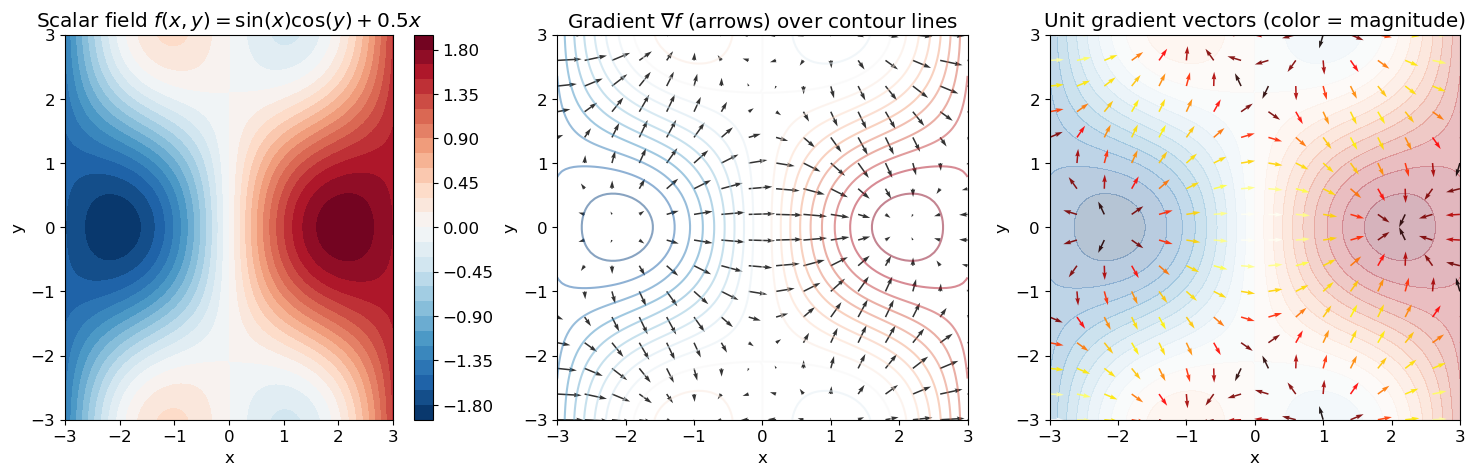

In [6]:
x = np.linspace(-3,3,100)
y = np.linspace(-3,3,100)

X, Y = np.meshgrid(x,y)
Z = scalar_field(X,Y)

x_q = np.linspace(-3, 3, 16)
y_q = np.linspace(-3, 3, 16)
Xq, Yq = np.meshgrid(x_q, y_q)
U,V = gradient_analytical(Xq, Yq)

fig, axes = plt.subplots(1,3,figsize=(18,5))

cs = axes[0].contourf(X,Y,Z, levels=30, cmap='RdBu_r')
axes[0].set_title('Scalar field $f(x,y) = \\sin(x)\\cos(y) + 0.5x$')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
plt.colorbar(cs, ax=axes[0])

axes[1].contour(X,Y,Z, levels=20, cmap='RdBu_r', alpha=0.5)
axes[1].quiver(Xq,Yq, U,V, color='black', alpha=0.8)
axes[1].set_title('Gradient $\\nabla f$ (arrows) over contour lines')
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')

grad_mag = np.sqrt(U**2 + V**2)
axes[2].contourf(X, Y, Z, levels=20, cmap='RdBu_r', alpha=0.3)
axes[2].quiver(Xq, Yq, U/grad_mag, V/grad_mag, grad_mag, cmap='hot', alpha=0.9)
axes[2].set_title('Unit gradient vectors (color = magnitude)')
axes[2].set_xlabel('x'); axes[2].set_ylabel('y')

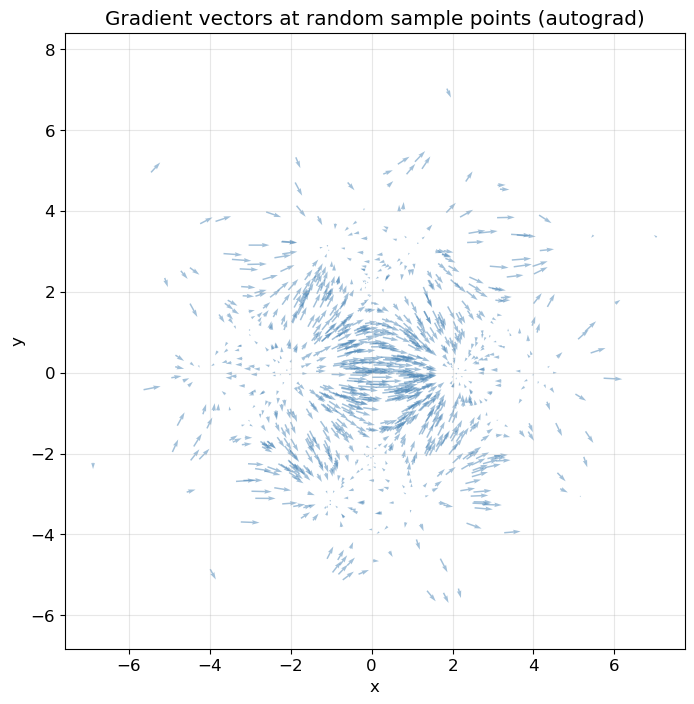

In [11]:
def batch_gradient(points):
    """Compute gradient of f(x,y) = sin(x)*cos(y) + 0.5*x at a batch of (x,y) points."""
    points = points.clone().requires_grad_(True)
    x, y = points[:, 0], points[:, 1]
    f = torch.sin(x) * torch.cos(y) + 0.5 * x
    # Sum so we can call backward (scalar output)
    f.sum().backward()
    return points.grad

# Random batch of 1000 points
pts = torch.randn(1000, 2) * 2
grads = batch_gradient(pts)

plt.figure(figsize=(8, 8))
plt.quiver(pts[:, 0].numpy(), pts[:, 1].numpy(),
           grads[:, 0].numpy(), grads[:, 1].numpy(),
           alpha=0.5, color='steelblue')
plt.title('Gradient vectors at random sample points (autograd)')
plt.xlabel('x'); plt.ylabel('y')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

In [27]:
import time
torch.manual_seed(0)
n = 2000
W1 = torch.randn(n, 256, dtype=torch.float64) / n**0.5
w2 = torch.randn(256, dtype=torch.float64) / 16

def E_fn(x):
    # A scalar 'energy' R^n -> R built from a random one-hidden-layer network.
    return torch.tanh(x @ W1) @ w2

x = torch.randn(n, dtype=torch.float64)

t0 = time.perf_counter()
xr = x.clone().requires_grad_(True)
E_fn(xr).backward()
g_autograd = xr.grad
t_ag = time.perf_counter() - t0

t0 = time.perf_counter()
h = 1e-6
E0 = E_fn(x)
I_n = torch.eye(n, dtype=torch.float64)
g_fd = torch.stack([(E_fn(x + h * I_n[i]) - E0) / h for i in range(n)])
t_fd = time.perf_counter() - t0

print(f"n = {n} inputs")
print(f"autograd:          {t_ag*1e3:8.1f} ms")
print(f"finite differences:{t_fd*1e3:8.1f} ms   ({n} extra evaluations)")
print(f"max |difference|:  {(g_autograd - g_fd).abs().max():.2e}  (finite-difference truncation error)")

F = lambda z: torch.tanh(z @ W1) @ W1.T
u = torch.randn(n, dtype=torch.float64)
_, vjp = torch.autograd.functional.vjp(F, x, u)      # u^T J
_, jvp = torch.autograd.functional.jvp(F, x, u)      # J u
J = torch.autograd.functional.jacobian(F, x)         # the expensive way: n passes
print(f"\nVJP matches u^T J: {torch.allclose(vjp, u @ J)},   JVP matches J u: {torch.allclose(jvp, J @ u)}")

n = 2000 inputs
autograd:               0.5 ms
finite differences:   128.2 ms   (2000 extra evaluations)
max |difference|:  1.36e-09  (finite-difference truncation error)

VJP matches u^T J: True,   JVP matches J u: True


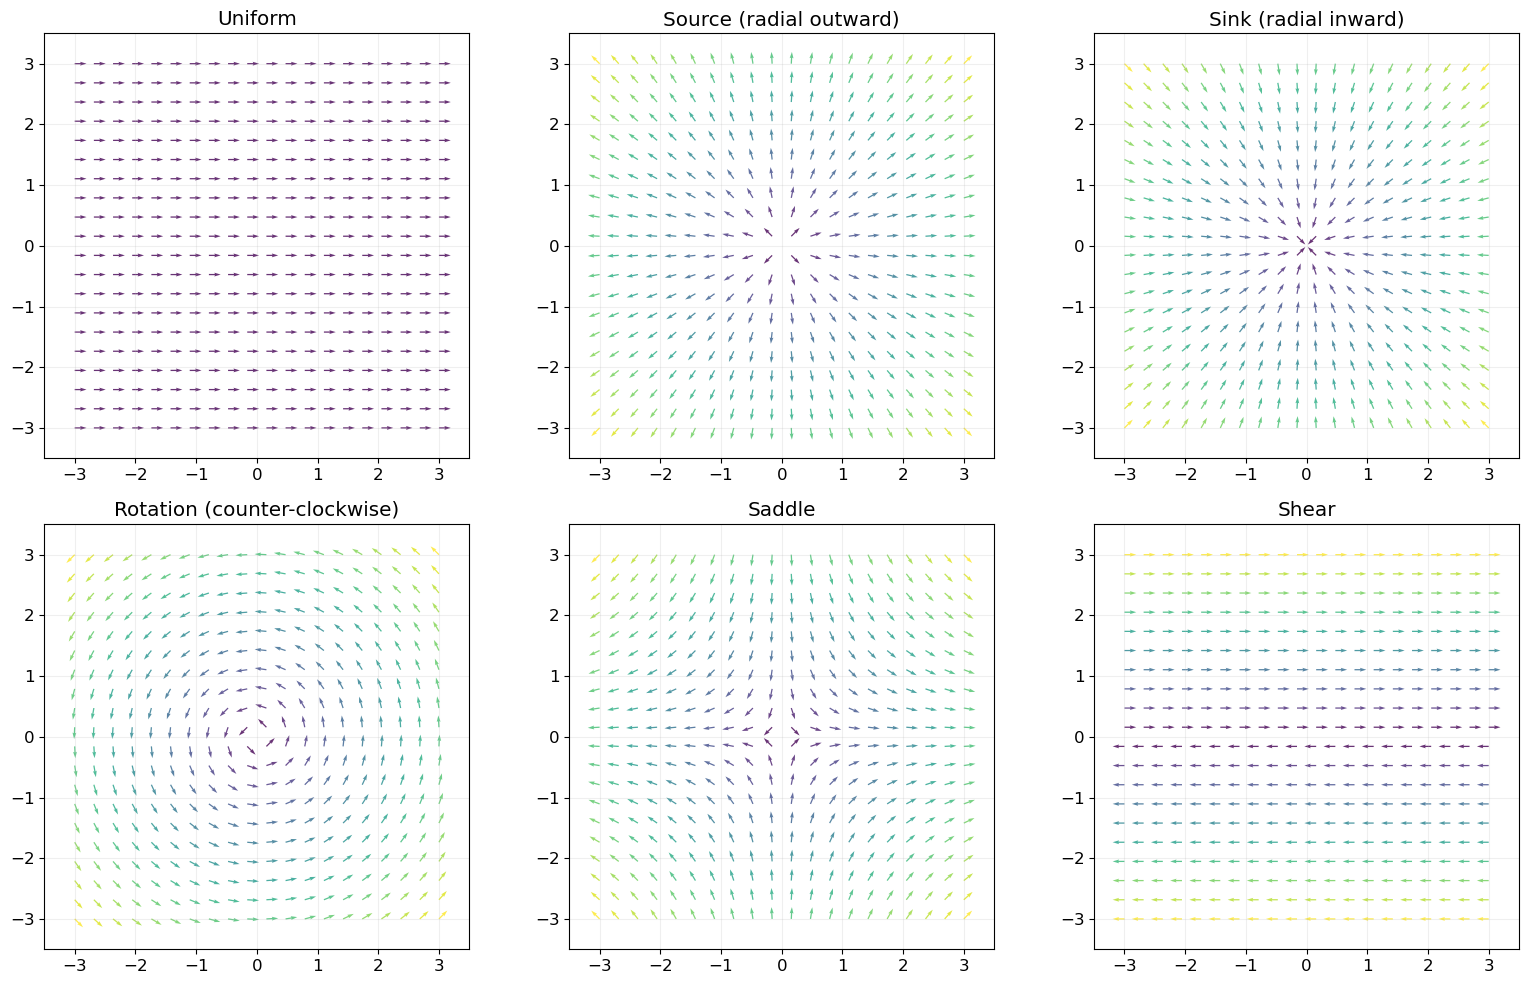

In [34]:
x = np.linspace(-3,3,20)
y = np.linspace(-3,3,20)
X,Y = np.meshgrid(x,y)

fields = {
    'Uniform': (np.ones_like(X), np.zeros_like(Y)),
    'Source (radial outward)': (X,Y),
    'Sink (radial inward)': (-X, -Y),
    'Rotation (counter-clockwise)': (-Y,X),
    'Saddle': (X,-Y),
    'Shear': (Y, np.zeros_like(X))
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, (U, V)) in zip(axes.flat, fields.items()):
    magnitude = np.sqrt(U**2 + V**2)
    magnitude = np.where(magnitude == 0, 1, magnitude)  # avoid /0
    ax.quiver(X, Y, U/magnitude, V/magnitude, magnitude, cmap='viridis', alpha=0.8)
    ax.set_title(name)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

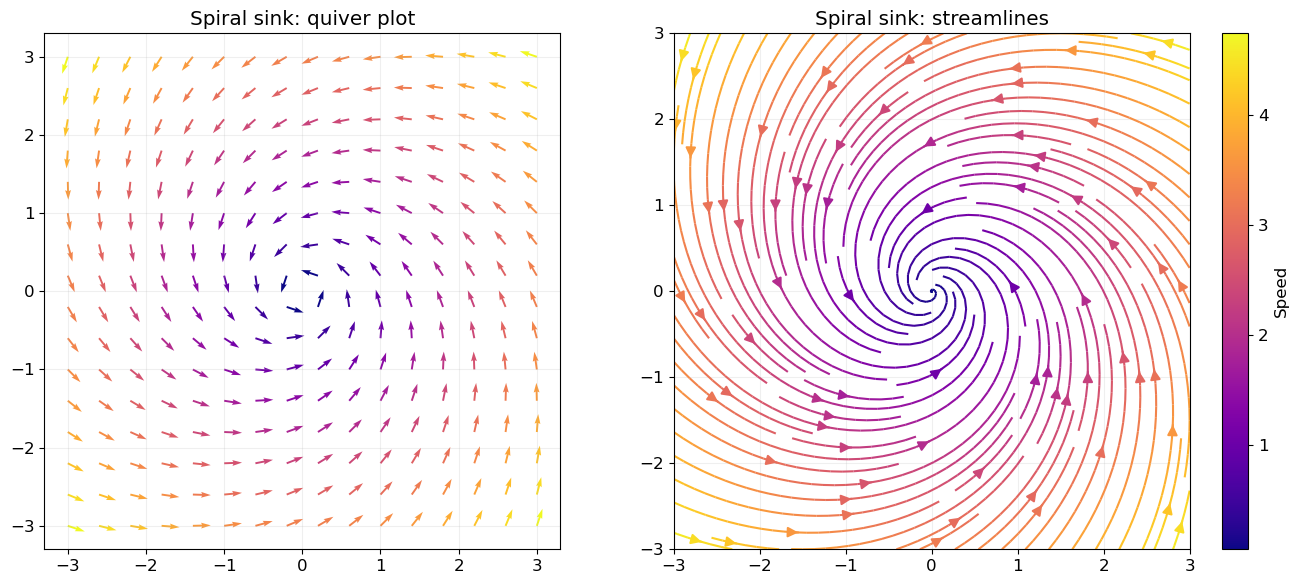

In [39]:
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

# A more interesting field: spiraling inward
U = -Y - 0.5 * X
V = X - 0.5 * Y
speed = np.sqrt(U**2 + V**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Quiver
x_q = np.linspace(-3, 3, 16)
y_q = np.linspace(-3, 3, 16)
Xq, Yq = np.meshgrid(x_q, y_q)
Uq = -Yq - 0.5 * Xq
Vq = Xq - 0.5 * Yq
mag_q = np.sqrt(Uq**2 + Vq**2)
ax1.quiver(Xq, Yq, Uq/mag_q, Vq/mag_q, mag_q, cmap='plasma')
ax1.set_title('Spiral sink: quiver plot')
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.2)

strm = ax2.streamplot(X, Y, U, V, color=speed, cmap='plasma',
                       density=1.5, linewidth=1.5, arrowsize=1.5)
ax2.set_title('Spiral sink: streamlines')
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.2)
plt.colorbar(strm.lines, ax=ax2, label='Speed')

plt.tight_layout()
plt.show()

In [4]:
# Compute divergence numerically (finite differences on a grid)

def divergence_numerical(U, V, dx, dy):
    """Compute divergence using central differences on a grid."""
    dFx_dx = np.gradient(U, dx, axis=1)  # dFx/dx along columns
    dFy_dy = np.gradient(V, dy, axis=0)  # dFy/dy along rows
    return dFx_dx + dFy_dy

# Compute divergence with PyTorch autograd
def divergence_autograd(field_fn, points):
    points = points.clone().requires_grad_(True)
    x, y = points[:, 0], points[:, 1]
    Fx, Fy = field_fn(x, y)
    
    # dFx/dx
    dFx_dx = torch.autograd.grad(Fx.sum(), points, create_graph=True)[0][:, 0]
    # dFy/dy
    dFy_dy = torch.autograd.grad(Fy.sum(), points, create_graph=True)[0][:, 1]
    
    return dFx_dx + dFy_dy

# Example: source field F = (x, y) -> divergence should be 2 everywhere
def source_field(x, y):
    return x, y

pts = torch.randn(5, 2)
div = divergence_autograd(source_field, pts)
print("Divergence of source field F=(x,y) at random points:")
print(f"  Values: {div.detach().numpy()}")
print(f"  Expected: 2.0 everywhere (dFx/dx=1, dFy/dy=1)")

Divergence of source field F=(x,y) at random points:
  Values: [2. 2. 2. 2. 2.]
  Expected: 2.0 everywhere (dFx/dx=1, dFy/dy=1)


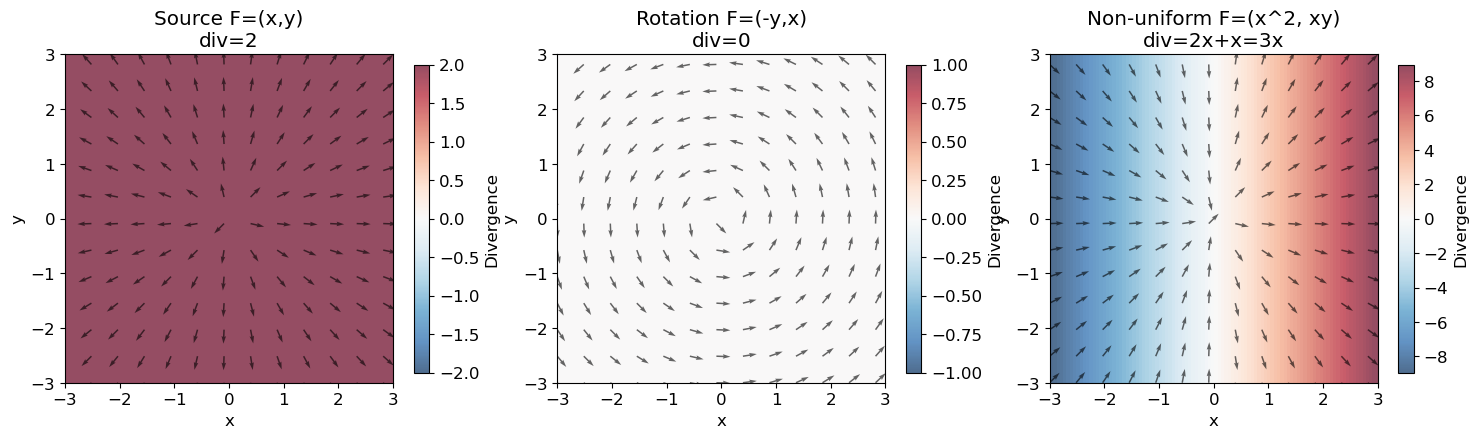

In [7]:
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
dx = x[1] - x[0]
dy = y[1] - y[0]
X, Y = np.meshgrid(x, y)

fields = {
    'Source F=(x,y)\ndiv=2': (X, Y),
    'Rotation F=(-y,x)\ndiv=0': (-Y, X),
    'Non-uniform F=(x^2, xy)\ndiv=2x+x=3x': (X**2, X*Y),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (U, V)) in zip(axes, fields.items()):
    div = divergence_numerical(U, V, dx, dy)
     # Color background by divergence
    vmax = max(abs(div.min()), abs(div.max()))
    if vmax == 0: vmax = 1
    im = ax.imshow(div, extent=[-3, 3, -3, 3], origin='lower',
                    cmap='RdBu_r', vmin=-vmax, vmax=vmax, alpha=0.7)
    
    # Overlay quiver
    skip = 8
    Us, Vs = U[::skip, ::skip], V[::skip, ::skip]
    mag = np.sqrt(Us**2 + Vs**2)
    mag = np.where(mag == 0, 1, mag)
    ax.quiver(X[::skip, ::skip], Y[::skip, ::skip],
              Us/mag, Vs/mag, color='black', alpha=0.6)
    
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label='Divergence', shrink=0.8)
    ax.set_xlabel('x'); ax.set_ylabel('y')

RuntimeError: One of the differentiated Tensors appears to not have been used in the graph. Set allow_unused=True if this is the desired behavior.

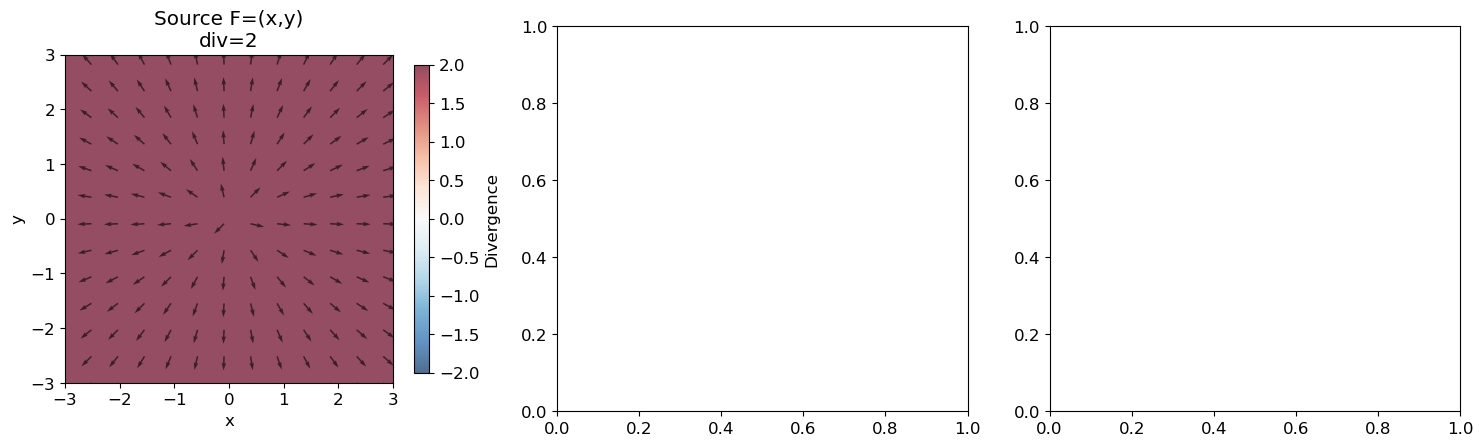

In [8]:
x_val = torch.linspace(-3, 3, 100)
y_val = torch.linspace(-3, 3, 100)
X_grid, Y_grid = torch.meshgrid(x_val, y_val, indexing='xy') 

# Requires_grad=True allows autograd to track operations on these coordinates
X = X_grid.flatten().clone().requires_grad_(True)
Y = Y_grid.flatten().clone().requires_grad_(True)

# 2. Define fields as functions so we can build a computation graph
fields = {
    'Source F=(x,y)\ndiv=2': lambda x, y: (x, y),
    'Rotation F=(-y,x)\ndiv=0': lambda x, y: (-y, x),
    'Non-uniform F=(x^2, xy)\ndiv=2x+x=3x': lambda x, y: (x**2, x*y),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, field_func) in zip(axes, fields.items()):
    # Forward pass: build the graph
    U, V = field_func(X, Y)
    
    # Backward pass: Compute analytical divergence (dU/dx + dV/dy)
    # grad_outputs acts like .sum().backward(), allowing batched scalar derivatives
    dU_dx = torch.autograd.grad(U, X, grad_outputs=torch.ones_like(U), retain_graph=True)[0]
    dV_dy = torch.autograd.grad(V, Y, grad_outputs=torch.ones_like(V))[0]
    
    # Sum the partial derivatives for divergence
    div = dU_dx + dV_dy
    
    # 3. Detach, reshape, and convert back to numpy for matplotlib
    U_np = U.detach().view(100, 100).numpy()
    V_np = V.detach().view(100, 100).numpy()
    div_np = div.detach().view(100, 100).numpy()
    X_np = X.detach().view(100, 100).numpy()
    Y_np = Y.detach().view(100, 100).numpy()

    # 4. Plotting (identical to your original matplotlib code)
    vmax = max(abs(div_np.min()), abs(div_np.max()))
    if vmax == 0: vmax = 1
    
    im = ax.imshow(div_np, extent=[-3, 3, -3, 3], origin='lower',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax, alpha=0.7)
    
    skip = 8
    Us, Vs = U_np[::skip, ::skip], V_np[::skip, ::skip]
    mag = np.sqrt(Us**2 + Vs**2)
    mag = np.where(mag == 0, 1, mag)
    ax.quiver(X_np[::skip, ::skip], Y_np[::skip, ::skip],
              Us/mag, Vs/mag, color='black', alpha=0.6)
    
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label='Divergence', shrink=0.8)
    ax.set_xlabel('x'); ax.set_ylabel('y')

plt.tight_layout()
plt.show()

In [12]:
def rotation_field(x,y):
    return -y, x

def curl_2d_autograd(field_fn, points):
    points = points.clone().requires_grad_(True)
    x, y = points[:,0], points[:,1]
    Fx, Fy = field_fn(x,y)

    dFy_dx = torch.autograd.grad(Fy.sum(), points, create_graph=True)[0][:,0]
    dFx_dy = torch.autograd.grad(Fx.sum(), points, create_graph=True)[0][:,1]

    return dFy_dx - dFx_dy

pts = torch.randn(5,2)
curl = curl_2d_autograd(rotation_field,pts)
print(curl.detach().numpy())

def gradient_field(x,y):
    return 2*x, 2*y

curl_grad = curl_2d_autograd(gradient_field,pts)
print(curl_grad.detach().numpy())

[2. 2. 2. 2. 2.]
[0. 0. 0. 0. 0.]


[[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]] 
 [[-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 ...
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]]


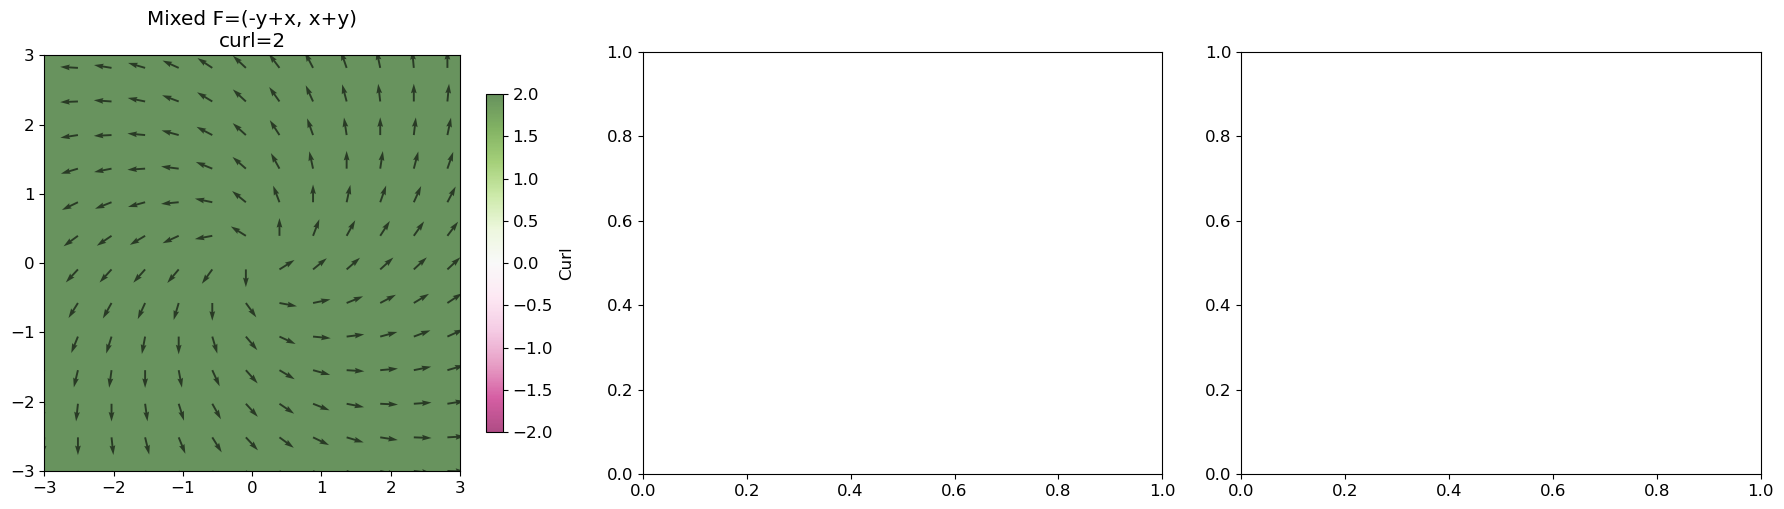

In [19]:
def curl_2d_numerical(U, V, dx, dy):
    """Curl in 2D: dFy/dx - dFx/dy"""
    dFy_dx = np.gradient(V, dx, axis=1)
    dFx_dy = np.gradient(U, dy, axis=0)
    print(dFy_dx, '\n', dFx_dy)
    return dFy_dx - dFx_dy

# Visualize curl for different fields
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
dx = x[1] - x[0]; dy = y[1] - y[0]
X, Y = np.meshgrid(x, y)

fields = {
    #'Rotation F=(-y,x)\ncurl=2': (-Y, X),
    #'Gradient F=(2x,2y)\ncurl=0': (2*X, 2*Y),
    'Mixed F=(-y+x, x+y)\ncurl=2': (-Y + X, X + Y),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (U, V)) in zip(axes, fields.items()):
    c = curl_2d_numerical(U, V, dx, dy)
    
    vmax = max(abs(c.min()), abs(c.max()))
    if vmax == 0: vmax = 1
    im = ax.imshow(c, extent=[-3, 3, -3, 3], origin='lower',
                    cmap='PiYG', vmin=-vmax, vmax=vmax, alpha=0.7)
    
    skip = 8
    Us, Vs = U[::skip, ::skip], V[::skip, ::skip]
    mag = np.sqrt(Us**2 + Vs**2)
    mag = np.where(mag == 0, 1, mag)
    ax.quiver(X[::skip, ::skip], Y[::skip, ::skip],
              Us/mag, Vs/mag, color='black', alpha=0.6)
    
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label='Curl', shrink=0.8)

plt.tight_layout()
plt.show()

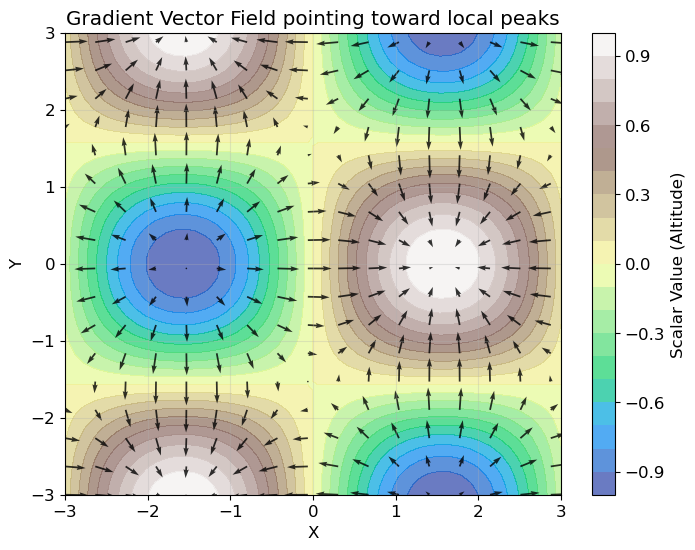

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup the PyTorch coordinate grid
x_val = torch.linspace(-3, 3, 50)
y_val = torch.linspace(-3, 3, 50)
X_grid, Y_grid = torch.meshgrid(x_val, y_val, indexing='xy') 

# Flatten and enable gradient tracking
X = X_grid.flatten().requires_grad_(True)
Y = Y_grid.flatten().requires_grad_(True)

# 2. Define the scalar field Z = f(X, Y)
# This evaluates the "altitude" at every single point
Z = torch.sin(X) * torch.cos(Y)

# 3. Calculate the gradient vector field [dU/dx, dU/dy]
# We use grad_outputs=torch.ones_like(Z) to compute gradients for the entire batch
dZ_dX = torch.autograd.grad(Z, X, grad_outputs=torch.ones_like(Z), retain_graph=True)[0]
dZ_dY = torch.autograd.grad(Z, Y, grad_outputs=torch.ones_like(Z))[0]

# 4. Detach and reshape back to 2D grids for plotting
Z_np = Z.detach().view(50, 50).numpy()
U_np = dZ_dX.detach().view(50, 50).numpy()  # The X-component of the gradient
V_np = dZ_dY.detach().view(50, 50).numpy()  # The Y-component of the gradient
X_np = X.detach().view(50, 50).numpy()
Y_np = Y.detach().view(50, 50).numpy()

# 5. Visualize the scalar field (contours) and vector field (quiver)
plt.figure(figsize=(8, 6))

# Plot the scalar field as a heat map
contour = plt.contourf(X_np, Y_np, Z_np, levels=20, cmap='terrain', alpha=0.7)
plt.colorbar(contour, label='Scalar Value (Altitude)')

# Overlay the gradient vector field
# We skip points so the arrows don't overlap into a solid black mess
skip = 3
plt.quiver(X_np[::skip, ::skip], Y_np[::skip, ::skip], 
           U_np[::skip, ::skip], V_np[::skip, ::skip], 
           color='black', alpha=0.8)

plt.title("Gradient Vector Field pointing toward local peaks")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
def transform(x):
    """A nonlinear 2D -> 2D transform: (x1, x2) -> (x1^2 + x2, sin(x1) + x2^2)"""
    return torch.stack([x[0]**2 + x[1], torch.sin(x[0]) + x[1]**2])

In [24]:
x0 = torch.tensor([1.0,2.0])

J = torch.autograd.functional.jacobian(transform, x0)
print(J)

tensor([[2.0000, 1.0000],
        [0.5403, 4.0000]])


In [25]:
transform(x0)

tensor([3.0000, 4.8415])

In [26]:
print(f"  [[2*x1, 1   ], [cos(x1), 2*x2]]")
print(f"  [[2.0,  1.0 ], [{np.cos(1.0):.4f}, 4.0  ]]")

  [[2*x1, 1   ], [cos(x1), 2*x2]]
  [[2.0,  1.0 ], [0.5403, 4.0  ]]


In [27]:
det_J = torch.det(J)

det_J.item()

7.459697723388672

In [28]:
det_J

tensor(7.4597)

In [30]:
from scipy.linalg import expm
from scipy.stats import multivariate_normal

A = np.array([[-0.5, -1.0],
              [ 1.0, -0.2]])          # a spiral sink: trace(A) = -0.7 < 0 -> density concentrates
t_end, n_steps = 2.0, 2000
dt = t_end / n_steps

rng = np.random.default_rng(0)
x = rng.standard_normal((5, 2))

In [36]:
logp = multivariate_normal(np.zeros(2), np.eye(2)).logpdf(x)

In [37]:
for _ in range(n_steps):
    x = x + dt * (x @ A.T)
    lopg = logp - dt * np.trace(A)

In [38]:
x

array([[ 0.02734248,  0.0749201 ],
       [-0.21918395,  0.28166762],
       [-0.02375065, -0.29333586],
       [-0.78433043,  0.47926494],
       [ 0.77091514, -0.16171766]])

In [39]:
logp

array([-1.8544842 , -2.04803594, -2.04638457, -3.13451256, -2.88501242])

In [40]:
cov_t = expm(A * t_end) @ expm(A * t_end).T
exact = multivariate_normal(np.zeros(2), cov_t).logpdf(x)
print("log p_t(x(t)) tracked along trajectories:", logp.round(4))
print("exact log-density of N(0, e^At e^A't):   ", exact.round(4))

log p_t(x(t)) tracked along trajectories: [-1.8545 -2.048  -2.0464 -3.1345 -2.885 ]
exact log-density of N(0, e^At e^A't):    [-0.4545 -0.6484 -0.6467 -1.7367 -1.4869]


In [41]:
np.random.default_rng(0)

Generator(PCG64) at 0x759397F28900

In [43]:
rng.standard_normal((5,2))

array([[-0.62327446,  0.04132598],
       [-2.32503077, -0.21879166],
       [-1.24591095, -0.73226735],
       [-0.54425898, -0.31630016],
       [ 0.41163054,  1.04251337]])

In [45]:
def euler_solve(v_fn, x0, t_span, n_steps):
    """
    Solve dx/dt = v(x, t) from t_span[0] to t_span[1].
    
    v_fn: function(x, t) -> dx/dt
    x0: initial condition (numpy array)
    t_span: (t_start, t_end)
    n_steps: number of Euler steps
    
    Returns: trajectory array of shape (n_steps+1, dim)
    """
    t_start, t_end = t_span
    h = (t_end - t_start) / n_steps
    
    x = np.array(x0, dtype=float)
    trajectory = [x.copy()]
    t = t_start
    
    for _ in range(n_steps):
        x = x + h * v_fn(x, t)
        t += h
        trajectory.append(x.copy())
    

In [47]:
def rk4_solve(v_fn, x0, t_span, n_steps):
    """4th-order Runge-Kutta ODE solver."""
    t_start, t_end = t_span
    h = (t_end - t_start) / n_steps
    
    x = np.array(x0, dtype=float)
    trajectory = [x.copy()]
    t = t_start
    
    for _ in range(n_steps):
        k1 = h * v_fn(x, t)
        k2 = h * v_fn(x + k1/2, t + h/2)
        k3 = h * v_fn(x + k2/2, t + h/2)
        k4 = h * v_fn(x + k3, t + h)
        x = x + (k1 + 2*k2 + 2*k3 + k4) / 6
        t += h
        trajectory.append(x.copy())
    
    return np.array(trajectory)

TypeError: 'NoneType' object is not subscriptable

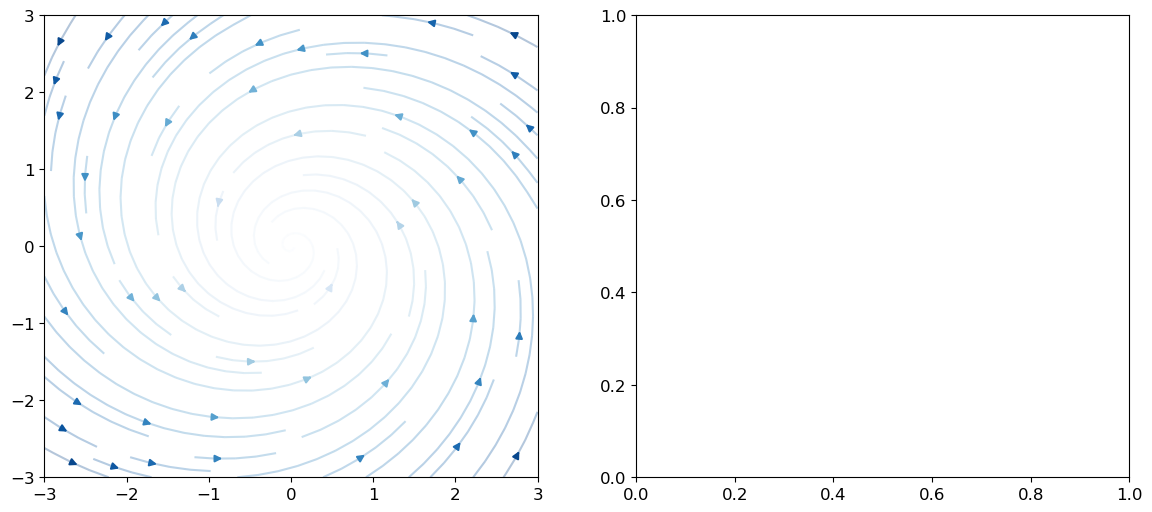

In [49]:
def spiral_velocity(x, t):
    """A time-independent spiral velocity field."""
    return np.array([-x[1] - 0.3*x[0], x[0] - 0.3*x[1]])

# Launch particles from different starting positions
n_particles = 12
angles = np.linspace(0, 2*np.pi, n_particles, endpoint=False)
start_positions = 2.5 * np.stack([np.cos(angles), np.sin(angles)], axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Background streamlines
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
U = -Y - 0.3*X
V = X - 0.3*Y

for ax, (solver, name) in [(ax1, (euler_solve, 'Euler')), (ax2, (rk4_solve, 'RK4'))]:
    speed = np.sqrt(U**2 + V**2)
    strm = ax.streamplot(X, Y, U, V, color=speed, cmap='Blues', density=0.8)
    strm.lines.set_alpha(0.3)

    colors = plt.cm.Set3(np.linspace(0, 1, n_particles))
    for i, x0 in enumerate(start_positions):
        traj = solver(spiral_velocity, x0, (0, 8), 200)
        ax.plot(traj[:, 0], traj[:, 1], '-', color=colors[i], linewidth=2, alpha=0.8)
        ax.plot(traj[0, 0], traj[0, 1], 'o', color=colors[i], markersize=8)  # start
        ax.plot(traj[-1, 0], traj[-1, 1], 's', color=colors[i], markersize=8)  # end
    
    ax.set_title(f'Particle trajectories ({name})')
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

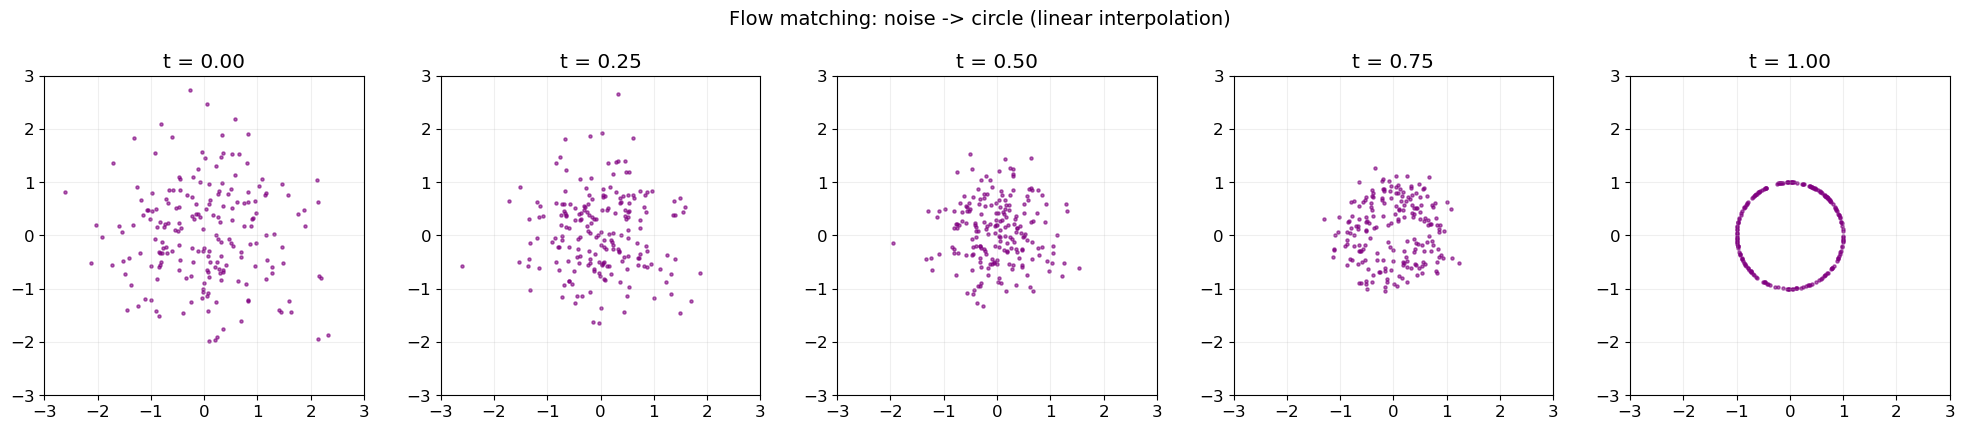

In [50]:
# Simple flow matching idea:
# Velocity field that takes noise at t=0 to target at t=1
# For a linear path: x(t) = (1-t)*x0 + t*x1
# Velocity: dx/dt = x1 - x0 (constant!)

np.random.seed(42)
n_particles = 200

# Source: random noise
x0_particles = np.random.randn(n_particles, 2)

# Target: points on a circle
angles = np.random.uniform(0, 2*np.pi, n_particles)
x1_particles = np.stack([np.cos(angles), np.sin(angles)], axis=1)

# Compute the straight-line velocity for each particle
velocities = x1_particles - x0_particles

# Trace each particle
n_time_steps = 50
t_values = np.linspace(0, 1, n_time_steps)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for idx, t in enumerate([0.0, 0.25, 0.5, 0.75, 1.0]):
    x_t = (1 - t) * x0_particles + t * x1_particles
    axes[idx].scatter(x_t[:, 0], x_t[:, 1], s=5, alpha=0.6, c='purple')
    axes[idx].set_xlim(-3, 3); axes[idx].set_ylim(-3, 3)
    axes[idx].set_title(f't = {t:.2f}')
    axes[idx].set_aspect('equal')
    axes[idx].grid(True, alpha=0.2)

plt.suptitle('Flow matching: noise -> circle (linear interpolation)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()